# POGOS: SOSSSISSE step-by-step

This is the basic steps to run just the SOSSISSE steps using a POGOS yaml 
file.

This assumes you have run `pogos_setup.py` first to generate the file structure and the yaml file mentioned below.



## Notes on running via notebook


You can turn off/on temporary saving to speed up many steps - but be warned if you change any parameters you must turn these off.

You can use `inst.params['GENERAL.USE_TEMPORARY'] = True` to load temporary files that were saved (and `False` to reload them).

By default this parameter should be `False` in your yaml file.

## Imports and notebook setup

In [1]:
import numpy as np

from sossisse.core import io
from sossisse.core import misc
from sossisse.general import general
from sossisse.general import plots

from pogos.resources import nb_funcs

/home/cook/miniconda3/envs/pogos-env/lib/python3.11/site-packages/pastasoss/soss_traces.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


## Yaml file definition

Set the path to the POGOS yaml file here

In [2]:
yaml_file = '/scratch3/jwst/pogos/pogos/resources/notebooks/soss_test.yaml'

## Initialization

POGOS and SOSSISSE initialization, don't change this section

In [3]:
# pogos sossisse init
inst = nb_funcs.sossisse_init(yaml_file)
# linear recon initialization
general.linear_recon_init(inst)


                       ╔════════════════════════╗
                       ║ ╔═╗╔═╗╔═╗╔═╗╦╔═╗╔═╗╔═╗ ║
                       ║ ╚═╗║ ║╚═╗╚═╗║╚═╗╚═╗║╣  ║
                       ║ ╚═╝╚═╝╚═╝╚═╝╩╚═╝╚═╝╚═╝ ║
                       ╚════════════════════════╝

************************************************************************************************************************
SOSSISSE: v0.1.062 - 2025-09-24
************************************************************************************************************************
11:11:00.66│         Using parameter file: /scratch3/jwst/pogos/pogos/resources/notebooks/soss_test.yaml

            ╔═══════════════════════════════════════════════════════════════════╗
            ║ ╦  ┬┌┐┌┌─┐┌─┐┬─┐   ╦═╗┌─┐┌─┐┌─┐┌┐┌   ╔╦╗┬─┐┌─┐┌─┐┌─┐┬┌─┐┌┬┐ ┐ ┌┐  ║
            ║ ║  ││││├┤ ├─┤├┬┘   ╠╦╝├┤ │  │ ││││    ║ ├┬┘├─┤├─┘├─┘│└─┐ │  │ ├┴┐ ║
            ║ ╩═╝┴┘└┘└─┘┴ ┴┴└─   ╩╚═└─┘└─┘└─┘┘└┘    ╩ ┴└─┴ ┴┴  ┴  ┴└─┘ ┴ ─┴─└─┘ ║
            ╚═══════════════════════════

False

## Update constants

Here you can update constants


In [4]:
# inst.params[PARAM_NAME] = VALUE

## Load the image, error and data quality images


In [5]:
# load the image, error and data quality
cube, err, dq = inst.load_data_with_dq()

## Apply the flat field

11:11:01.40│ Applying flat field to data


100%|██████████| 153/153 [00:00<00:00, 713.19it/s]


11:11:02.10│ Plotting graph: flatfield.png
11:11:02.49│ Plotting graph: flatfield.pdf


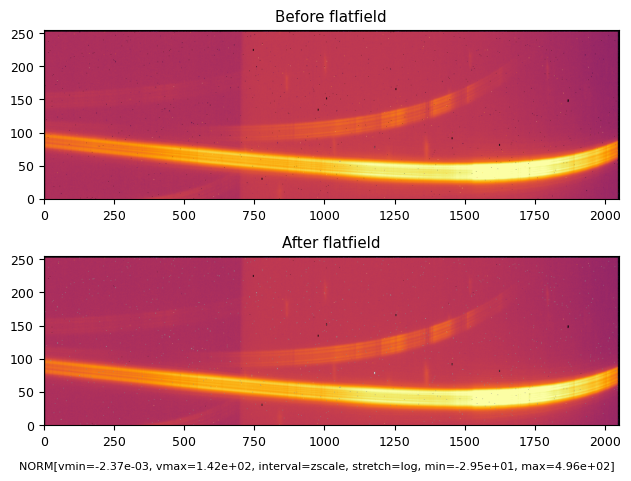

In [6]:
# Apply the flat field
cube, err, dq = inst.apply_flat_field(cube, err, dq)

## Keep only certain Data Quality flags

In [7]:
# apply the dq to the cube
cube, err = inst.apply_dq(cube, err, dq)

11:11:03.56│ Accepting DQ = 0
11:11:03.69│ Accepting DQ = 2


## Remove background


plotting parameters you may want to change:
- `inst.params['WLC.PLOT.BACKGROUND_VLIM']  = [2, 10]`
- `inst.params['WLC.PLOT.BACKGROUND_VLIM_TYPE']  = 'absolute'`

In [8]:
cube_old = np.array(cube)

11:11:04.28│ Apply the background model correction
11:11:05.09│         Tweaking the position of the background


100%|██████████| 51/51 [00:02<00:00, 20.40it/s]

11:11:07.61│         Optimal background offset 1.358 pix



100%|██████████| 153/153 [00:00<00:00, 1749.47it/s]


11:11:07.91│ Plotting graph: background_corr.png
11:11:08.31│ Plotting graph: background_corr.pdf


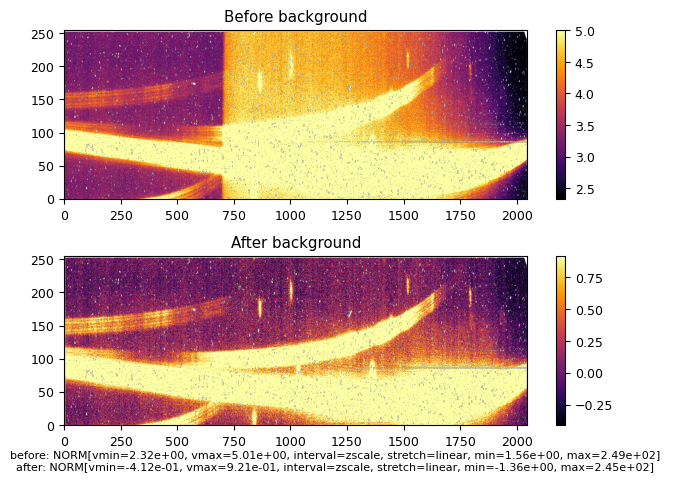

In [9]:
# remove the background
cube, err = inst.remove_background(cube_old, err)

## Low pass the data

11:11:09.52│         Low pass filtering the data


100%|██████████| 153/153 [00:03<00:00, 42.47it/s]


11:11:13.52│ Plotting graph: lowpass_corr.png
11:11:14.29│ Plotting graph: lowpass_corr.pdf


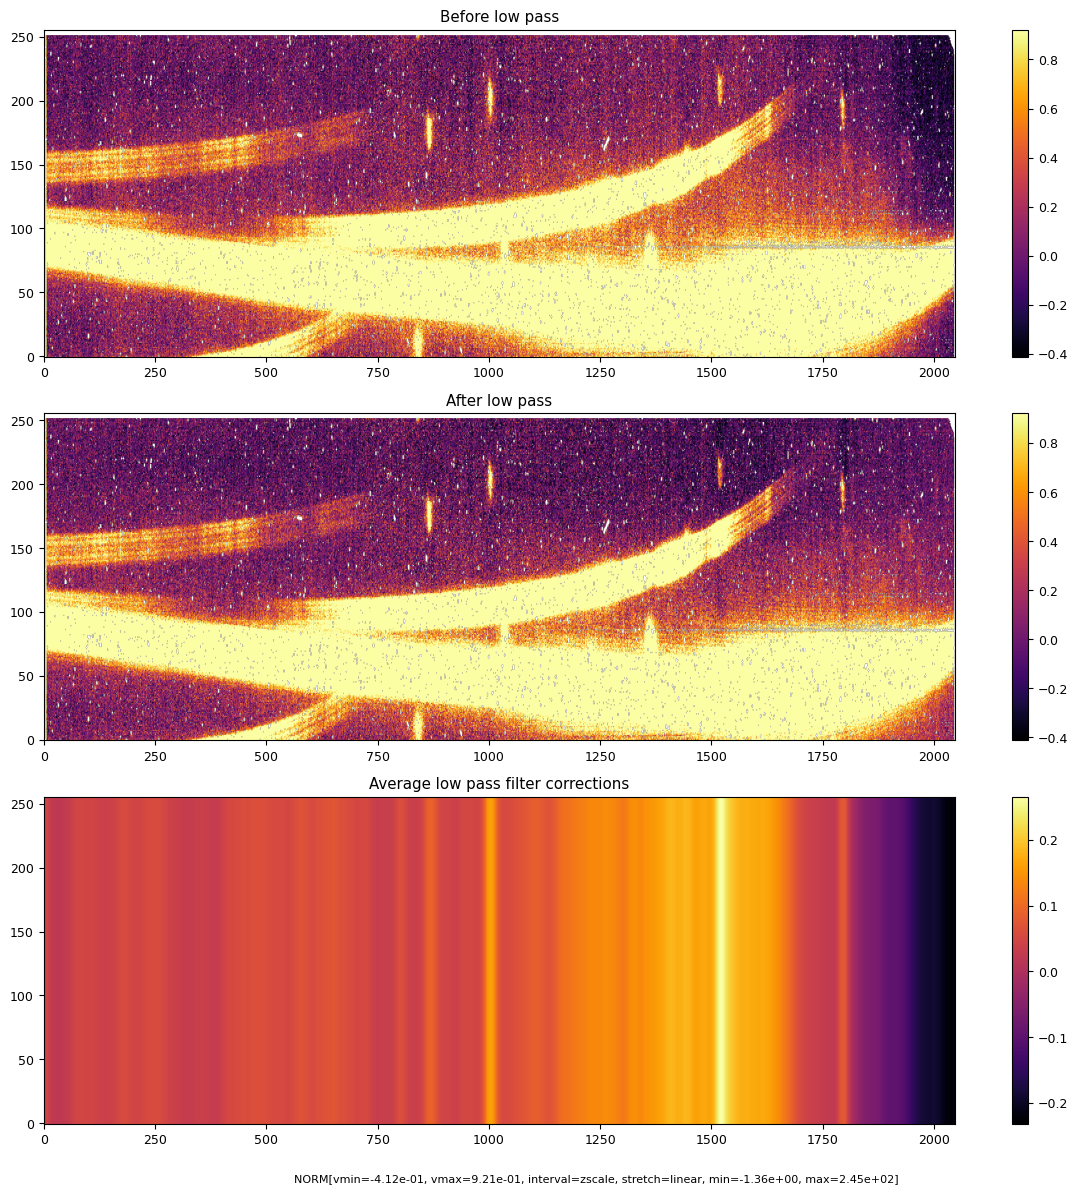

In [10]:
# low pass the data
cube, err = inst.low_pass_filter(cube, err)

## Patch isolated bad pixels

11:11:15.78│  Removing isolated NaNs


153it [00:30,  4.96it/s]


11:11:46.86│ Plotting graph: isolated_badpixels.png
11:11:47.54│ Plotting graph: isolated_badpixels.pdf


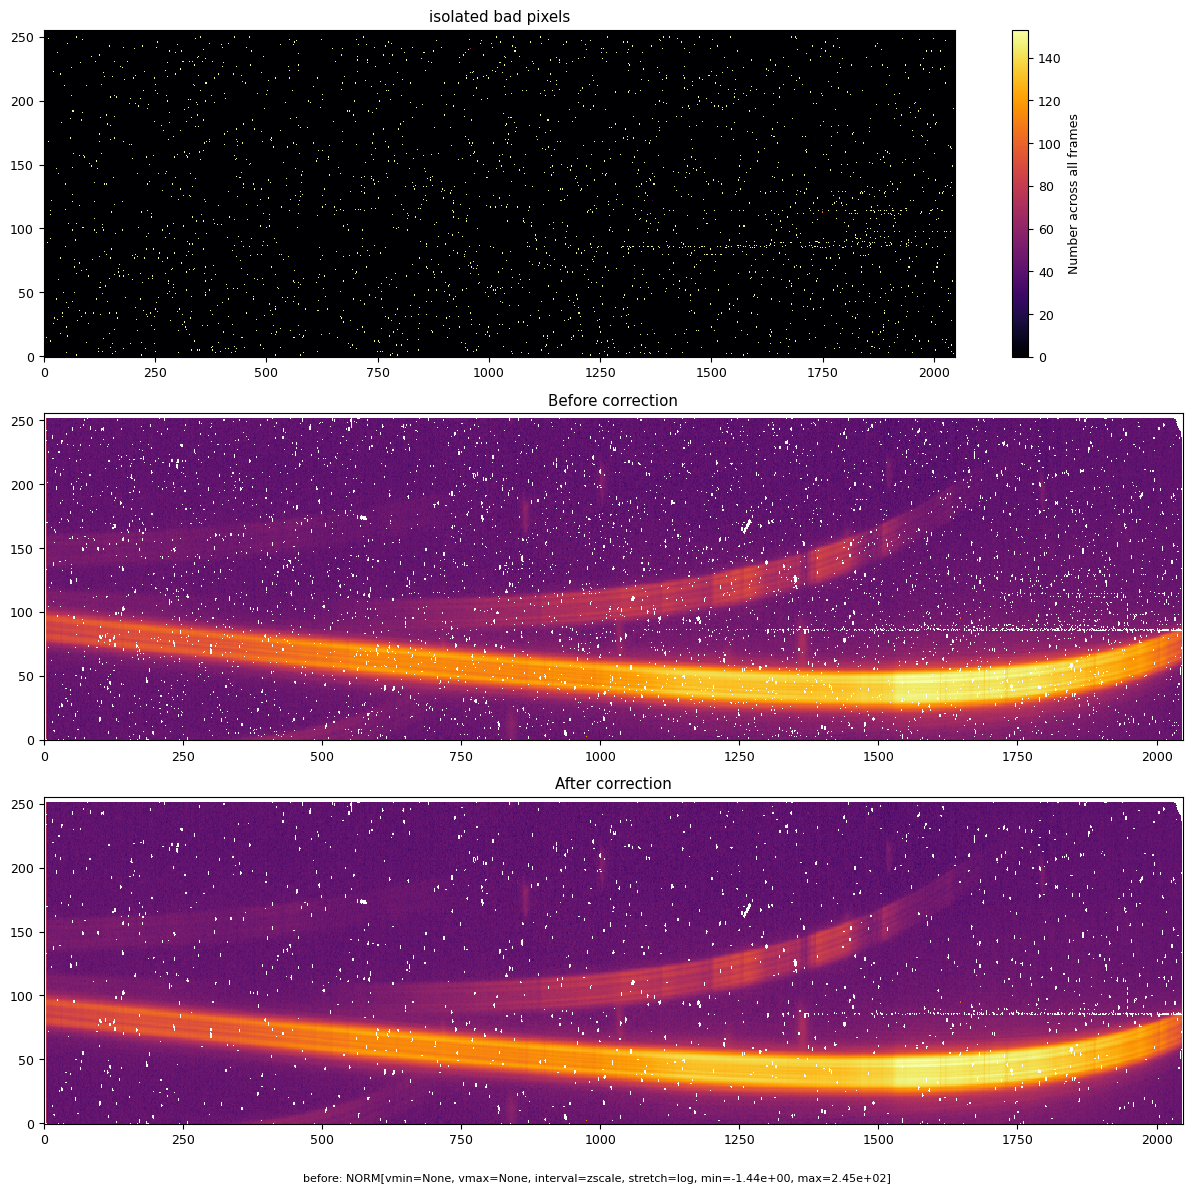

100%|██████████| 153/153 [00:00<00:00, 163.61it/s]

11:11:49.54│ Plotting graph: isolated_pixel_corr_stamps.png


11:11:49.86│ Plotting graph: isolated_pixel_corr_stamps.pdf


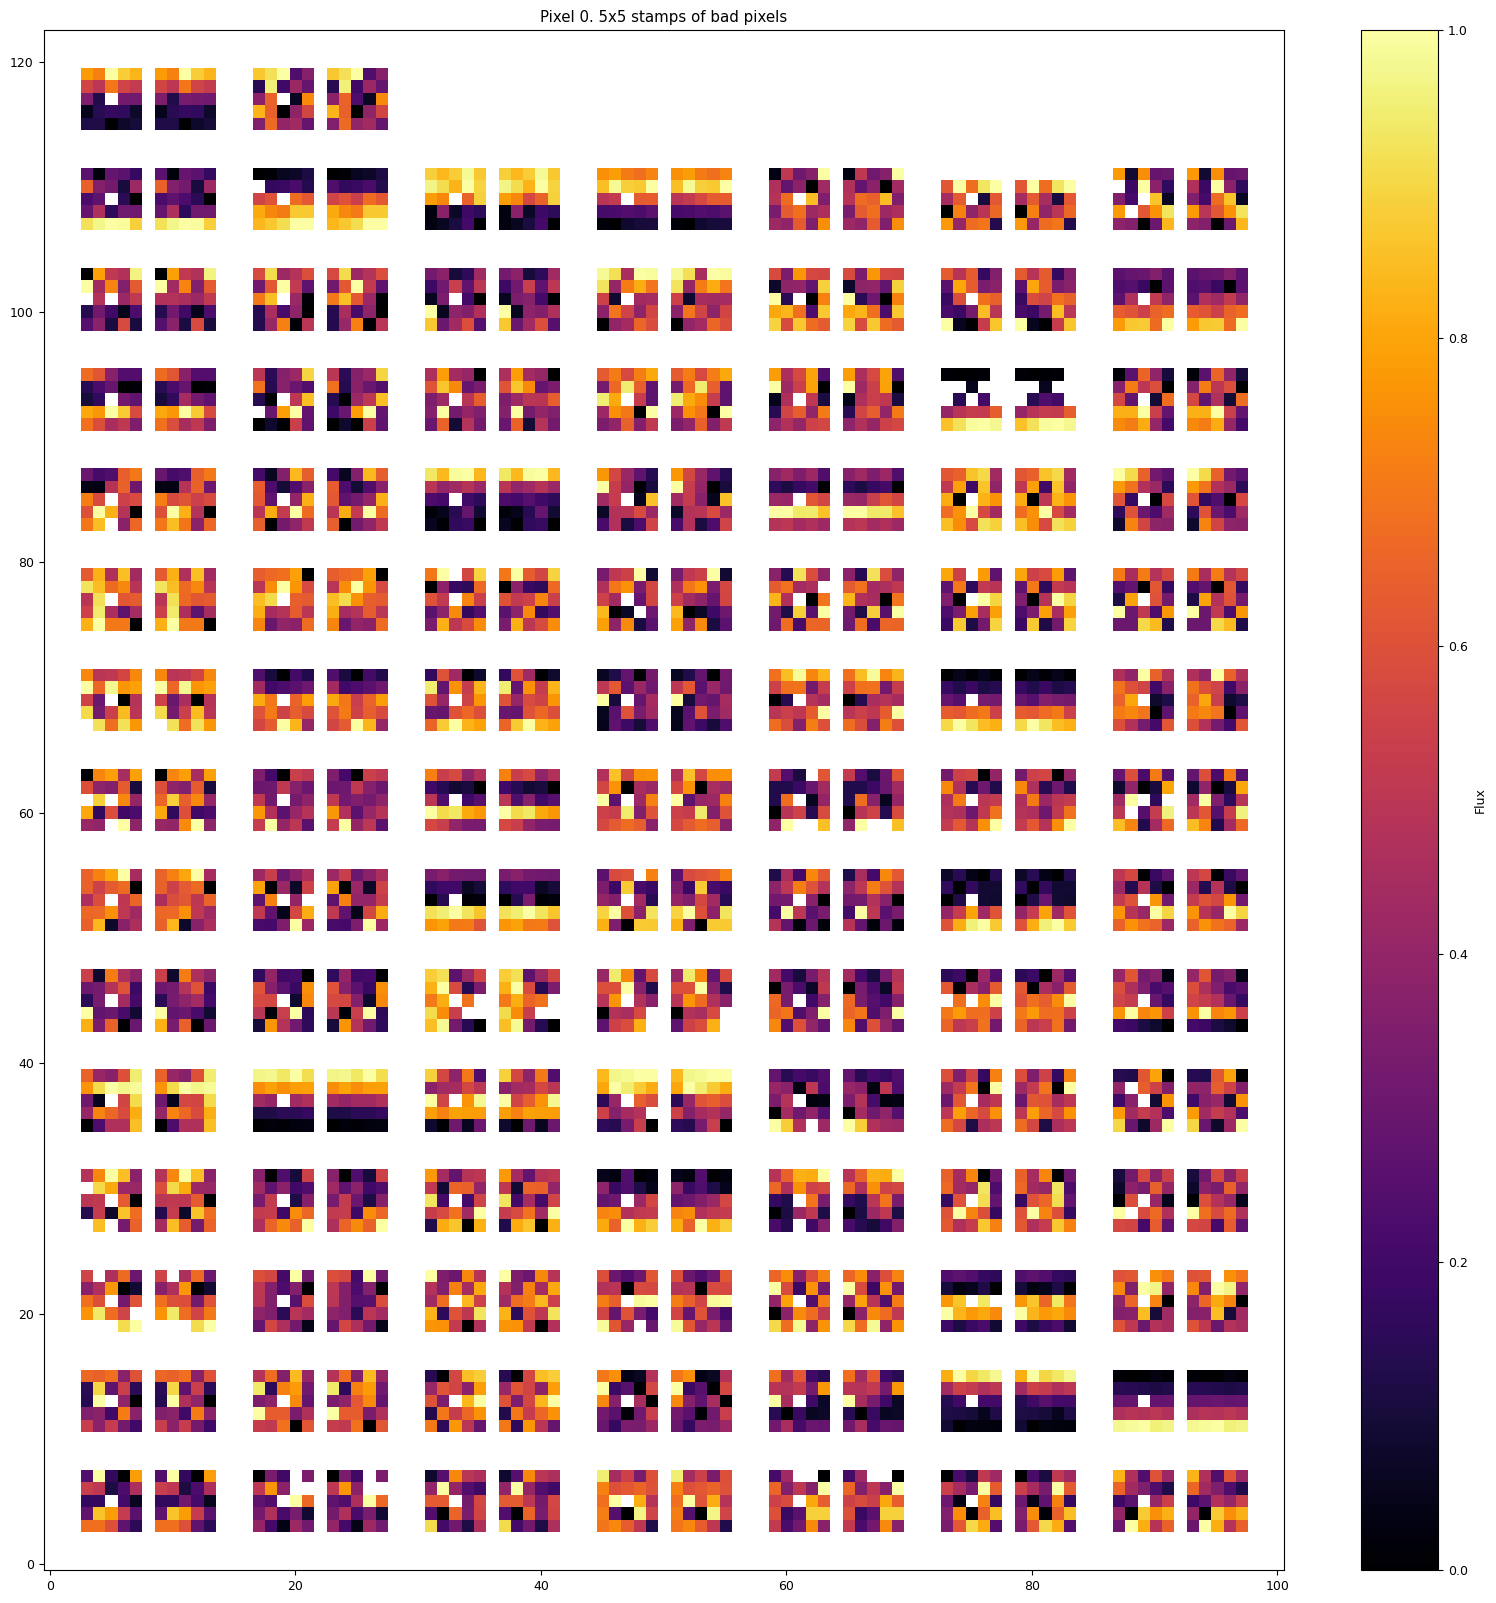

In [11]:
# for each slice of the cube, isolated bad pixels are interpolated with the
# value of their 4 neighbours.
cube, err = inst.patch_isolated_bads(cube, err)

## Remove cosmic rays

11:11:50.53│ We remove cosmisc rays
11:11:50.54│         Calculating median of 1-sigma cube


100%|██████████| 153/153 [00:00<00:00, 401.07it/s]


11:12:20.35│ Plotting graph: cosmic_rays_corr.png
11:12:20.98│ Plotting graph: cosmic_rays_corr.pdf


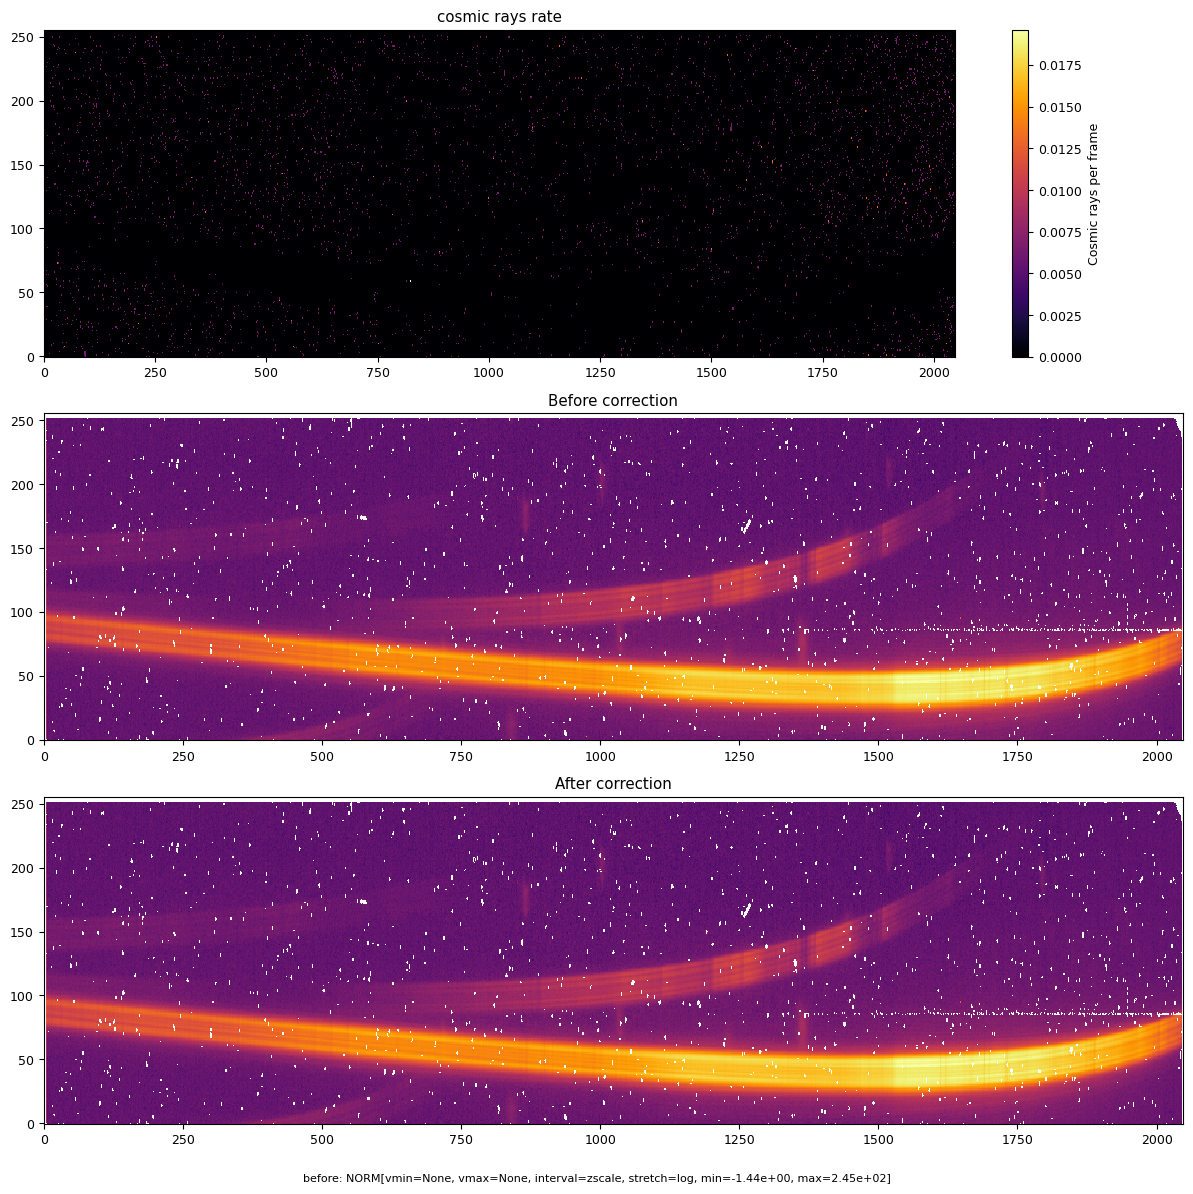

In [12]:
# whether to use temporary files
inst.params['GENERAL.USE_TEMPORARY'] = True
# remove cosmic rays with a sigma cut
cube = inst.remove_cosmic_rays(cube)

## Use PASTASOSS (if required)

In [ ]:
# optimize trace position
inst.optimize_trace_mask()

## Get the trace mask

In [ ]:
# get the trace map
trace_mask = inst.get_trace_mask(no_plot=False, images=[cube[0], cube[-1]],
                                 labels=['First frame', 'Last frame'])

## Create the median stack

In [ ]:
cube, med, amps, transit_invsout = inst.create_median_stack(cube)

## Differential 1/f correction

In [ ]:
cube = inst.clean_residual_1f(cube, err, med, amps, trace_mask)

## Recenter the trace position

In [ ]:
trace_mask = inst.recenter_trace_position(trace_mask, med)

## PCA Analysis

Note turn this off with 

```
SOSSISSE.WLC.LMODEL.FIT_PCA = False
```

In [ ]:
# construct the principal component model from the out of transit domain
# using pca (we deal with not fitting the PCA inside)
pcas = inst.fit_pca(cube, err, med, trace_mask)

## Linear reconstruction


Following Equation A1 from Lim et al. 2023 (https://iopscience.iop.org/article/10.3847/2041-8213/acf7c4/pdf)

Flux = amp[0] x M + amp[1] x dM/dx + amp[2] x dM/dy + amp[3] x dM/dtheta + amp[4] x d2M/dy2


### Step 1: Get gradients

In [ ]:
# get the gradients
dx, dy, rotxy, ddy, med_clean = inst.get_gradients(med)

### Step 2: set up the mask for linear reconstruction

In [ ]:
# set up the mask for trace position
mask_out = inst.get_linear_recon_mask(med, trace_mask)
mask_trace_pos, x_order0, y_order0, x_trace_pos, y_trace_pos = mask_out

## Step 3: Construct and run the linear reconstruction

In [ ]:

# setup the linear reconstruction vector based on the input parameters
lvector = inst.setup_linear_reconstruction(med, dx, dy, rotxy, ddy,
                                           pcas)
# -----------------------------------------------------inst--------------------
# find the best linear combination of scale/dx/dy/rotation from lvector
# amps is a vector with the amplitude of all 4 fitted terms
# amps[0] -> amplitude of trace
# amps[1] -> dx normalized on reference trace
# amps[2] -> dy normalized on reference trace
# amps[3] -> rotation (in radians) normalized on reference trace
# amps[4] -> 2nd derivative in y [if option activated]

# Flux = amp[0] x M + amp[1] x dM/dx + amp[2] x dM/dy + amp[3] x dM/dtheta 
#        + amp[4] x d2M/dy2
# -------------------------------------------------------------------------
l_out = inst.get_linear_coeffs(cube, err, med, mask_trace_pos,
                               lvector, x_trace_pos, y_trace_pos,
                               x_order0, y_order0)
# get outputs of apply_amp_recon
#  Note the recon model has been subtracted from the cube in order to 
#  later to differential spectral extraction
ltable, lrecon, valid_cube, rescube = l_out

## Linear recon analysis


In [ ]:
# Add integration times to the table
ltable = inst.add_integration_times(ltable)
# -------------------------------------------------------------------------
# normalize the trace but a normalization factor
ltable = inst.normalize_sum_trace(ltable)
# -------------------------------------------------------------------------
# print the rms baseline for all methods
for method in inst.rms_baselines():
    # calculate the rms for this method
    rms_method = inst.get_rms_baseline(ltable['amplitude'], method=method)
    # print this
    msg = '{0}, rms = {1:.1f}ppm'.format(method, rms_method * 1e6)
    misc.printc(msg, 'number')
# -------------------------------------------------------------------------
# calculate and print the effective wavelength
inst.get_effective_wavelength()

## Preemptively correct the cube for spectral extraction 

This corrects the whole time series based on the out-of-transit slope 
- use very carefuly.


This is done here so we only save the cube once to disk 
(and we don't have to reopen it)

In [ ]:

# per pixel baseline - for each spectral pixel column, subtract a polynomial 
# (based on out-of-transit data) - use carefully!
# if inst.params['WLC.GENERAL.PER_PIXEL_BASELINE_CORRECTION']:
#     misc.printc('Performing per-pixel baseline subtraction', 'info')
#     rescube = inst.per_pixel_baseline(rescube, valid_cube)

## Save and plot the linear recon results

In [ ]:
# =========================================================================
# write files
# =========================================================================
inst.save_wlc_results(rescube, err, lrecon, ltable)
# =========================================================================
# Plots and Summary HTML
# =========================================================================
# plot the stability plot
plots.plot_stability(inst, ltable)
# -------------------------------------------------------------------------
# write the yaml file to html
io.summary_html(inst.params)

## Spectral extraction setup

In [ ]:
# get parameters from instrumental parameters
objname = inst.params['INPUTS.OBJECTNAME']
# print the white light curve splash
print(misc.art('Spectral timeseries ' + objname, 'blue', 'CYAN'))
# -------------------------------------------------------------------------
# load temporary filenames (should be run before science starts)
inst.define_filenames()
# -------------------------------------------------------------------------
# plot / save storage
storage = dict()
# get the trace orders
trace_orders = inst.get_trace_orders()

## Processing trace order loop

This is done for each order, you could remove the for loop and just set the
trace order individually
```
trace_order = 1
```

In [ ]:
# loop around trace orders
for trace_order in trace_orders:
    # print progress
    misc.printc('Processing trace order {0}'.format(trace_order), 'alert')
    # ---------------------------------------------------------------------
    # load data for this trace order
    indata = inst.load_input_spec_data(trace_order)
    med, dx, dy, rotxy, ddy, med_clean, residual, err = indata[:8]
    recon, ltable, posmax, throughput, wavegrid = indata[8:]
    # ---------------------------------------------------------------------
    # create the SED
    sp_sed = inst.create_sed(med, residual, wavegrid, posmax, throughput,
                             med_clean, trace_order)
    # ---------------------------------------------------------------------
    # load the model (and deal with masking order zero if required)
    model = inst.load_model(recon, med)
    # ---------------------------------------------------------------------
    # spectrum is the ratio of the residual to the trace model
    spec, spec_err = inst.ratio_residual_to_trace(model, err, residual,
                                                  posmax)
    # ---------------------------------------------------------------------
    # # remove the out-of-transit trend on the spectrum
    # if inst.params['SPEC_EXT.REMOVE_TREND']:
    #     spec = inst.remove_trend_spec(spec)
    # -----------------------------------------------------------------
    # reshape the amplitudes into an image
    amp_image = np.repeat(np.array(ltable['amplitude']), spec.shape[1])
    amp_image = amp_image.reshape(spec.shape)
    # add this gray component onto the spectrum
    spec2 = spec + amp_image
    # ---------------------------------------------------------------------
    # plot the spec2 data
    plots.plot_spectral_timeseries(inst, spec2, trace_order)
    # ---------------------------------------------------------------------
    # # remove the out-of-transit trend on the photometric time series
    # if inst.params['SPEC_EXT.REMOVE_TREND']:
    #     ltable = inst.remove_trend_phot(spec, ltable)
    # # ---------------------------------------------------------------------
    # # compute or set transit depth
    # transit_depth = inst.get_transit_depth(ltable)
    # ---------------------------------------------------------------------
    # # get the in-transit spectrum
    # isout = inst.intransit_spectrum(spec, spec_err)
    # spec_in, spec_err_in, spec_err_out = isout
    # ---------------------------------------------------------------------
    # # bin the data by RESOLUTION_BIN
    # wave_bin, flux_bin, flux_bin_err = inst.bin_spectrum(wavegrid,
    #                                                      spec_in,
    #                                                      spec_err_in)
    # ---------------------------------------------------------------------
    # push into storage for outside loop
    storage = general.trace_storage(storage, trace_order, wavegrid, sp_sed,
                                    throughput, spec, spec_err, ltable, spec2)
    # ---------------------------------------------------------------------
    inst.save_spe_results(storage[trace_order], trace_order)

## Spectral extraction plots and saving

In [ ]:
# plot the SED
plots.plot_full_sed(inst, storage)
# -------------------------------------------------------------------------
# convert sossisse to eureka products
inst.to_eureka(storage)
# -------------------------------------------------------------------------
# write the yaml file to html
io.summary_html(inst.params)